# Input and source-data diagnostics

This notebook inventories and plots the five inputs from the [published FACTS VLM archive](https://doi.org/10.5281/zenodo.18199757) and the **corrected production implementation** in this repository. No legacy model or earlier baseline is used.

All plots are embedded for GitHub viewing. To rerun, install the optional diagnostics dependencies and provide the input files as described in [README.md](README.md). Inputs are never downloaded automatically, and all standalone figures and datasets are written under ignored `data/`.

Upward land velocity is positive; its relative sea-level (RSL) contribution has the opposite sign. GIA's RSL rate also includes its sea-surface effect.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from IPython.display import display

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/oelsmann24_verticallandmotion").is_dir()
)
sys.path.insert(0, str(ROOT))
from diagnostics import helpers as dh  # noqa: E402

# Change these paths or set the corresponding environment variables.
INPUT_DIR = Path(os.environ.get("VLM_INPUT_DIR", ROOT / "data/inputs/reference"))
OUTPUT_DIR = Path(
    os.environ.get("VLM_DIAGNOSTICS_DIR", ROOT / "data/diagnostics/shared_notebooks")
)
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

config = dh.Config(input_dir=INPUT_DIR, output_dir=OUTPUT_DIR)
config.paths()
print("Input files found; production package imported from this checkout.")

Input files found; production package imported from this checkout.


## File, variable, dimension and unit inventory

This includes all variables in the source files, even variables not used by this module. The example glacier-quantile input is retained for interface compatibility; its values do not enter the VLM calculation. The coast file has a misleading historical filename: its native spacing is 0.01°, not 1°. Large rasters are subsampled during preprocessing.

In [2]:
table = dh.inventory(config)
display(table)
config.output_dir.mkdir(parents=True, exist_ok=True)
table.to_csv(config.output_dir / "input_inventory.csv", index=False)

rec = xr.open_dataset(config.input_dir / "VLM_reconstruction.nc")
gps = xr.open_dataset(config.input_dir / "NGL14_CMR_corrected.nc")
gia = xr.open_dataset(config.input_dir / "GIA_stats.nc")
gia = gia.assign_coords(lon=(gia.lon + 180) % 360 - 180).sortby("lon")
pp = dh.preprocess(config)
fields = pp["VLM_REC_MERGED"]
weights = pp["weights"]
display(
    pd.DataFrame(
        [
            {
                "dataset": "Reconstruction",
                "source_sites": rec.sizes["x"],
                "first_year": int(rec.time.dt.year.min()),
                "last_year": int(rec.time.dt.year.max()),
            },
            {"dataset": "GNSS", "source_sites": gps.sizes["x"]},
        ]
    )
)

,file,variable,dimensions,dtype,units
0,VLM_reconstruction.nc,Full_VLM_reconstruction_mean,"{'time': 175, 'x': 20269}",float64,m
1,VLM_reconstruction.nc,Full_VLM_reconstruction_uncertainty,"{'time': 175, 'x': 20269}",float64,m
2,VLM_reconstruction.nc,VLM_trend_time_series_mean,"{'time': 175, 'x': 20269}",float64,m
3,VLM_reconstruction.nc,VLM_trend_time_series_uncertainty,"{'time': 175, 'x': 20269}",float64,m
4,VLM_reconstruction.nc,VLM_trend_coefficient_mean,{'x': 20269},float64,m/year
5,VLM_reconstruction.nc,VLM_trend_coefficient_uncertainty,{'x': 20269},float64,m/year
6,VLM_reconstruction.nc,VLM_EOF_time_series_mean,"{'time': 175, 'x': 20269}",float64,m
7,VLM_reconstruction.nc,VLM_EOF_time_series_uncertainty,"{'time': 175, 'x': 20269}",float64,m
8,VLM_reconstruction.nc,VLM_present_day_trend_coefficient_mean,{'x': 20269},float64,m/year
9,VLM_reconstruction.nc,VLM_present_day_trend_uncertainty,{'x': 20269},float64,m/year


,dataset,source_sites,first_year,last_year
0,Reconstruction,20269,1995.0,2169.0
1,GNSS,14476,NaN,NaN


## Reconstruction trend, uncertainty and footprint

The black contours bound occupied 0.25° cells; they indicate where input points exist, not a calibrated boundary of validity. Colors saturate beyond the displayed limits (normally the 98th percentile); the source values are not clipped or modified.

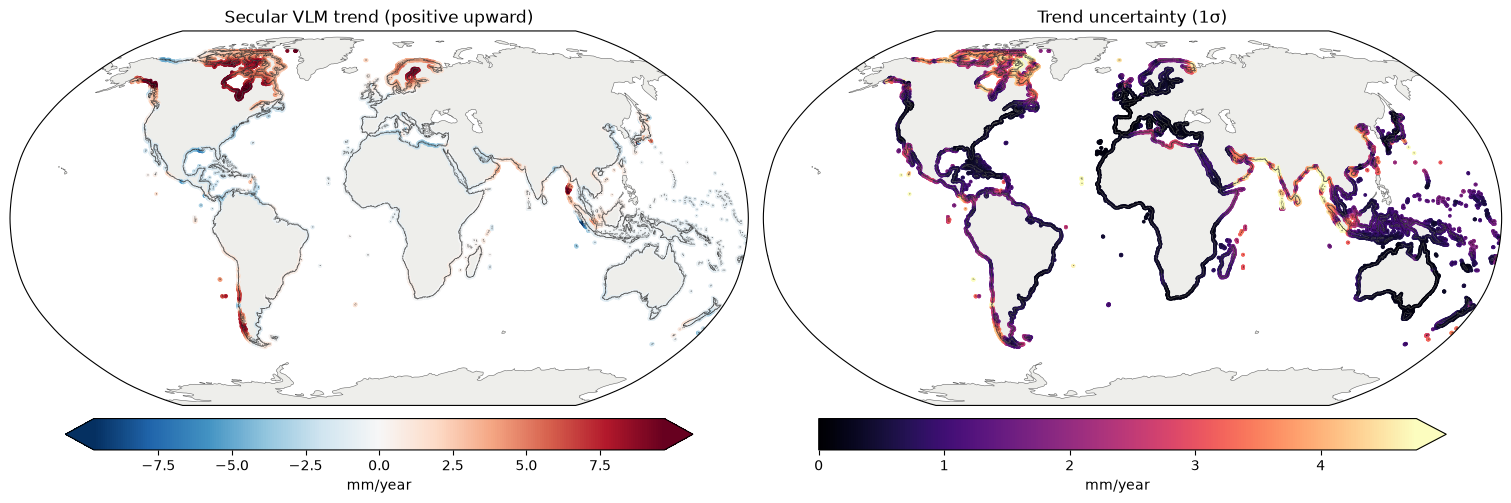

In [3]:
fig, axes = dh.map_axes(1, 2, figsize=(15, 5.5))
lon_edges, lat_edges = np.arange(-180, 180.25, 0.25), np.arange(-90, 90.25, 0.25)
footprint = (
    np.histogram2d(rec.lat, (rec.lon + 180) % 360 - 180, bins=[lat_edges, lon_edges])[0]
    > 0
)
for ax, name, title, cmap in zip(
    axes.flat,
    ["VLM_trend_coefficient_mean", "VLM_trend_coefficient_uncertainty"],
    ["Secular VLM trend (positive upward)", "Trend uncertainty (1σ)"],
    ["RdBu_r", "magma"],
):
    dh.map_points(ax, rec.lon, rec.lat, rec[name] * 1000, title, "mm/year", cmap=cmap)
    ax.contour(
        (lon_edges[1:] + lon_edges[:-1]) / 2,
        (lat_edges[1:] + lat_edges[:-1]) / 2,
        footprint,
        levels=[0.5],
        colors="black",
        linewidths=0.15,
        transform=ccrs.PlateCarree(),
    )
dh.save_figure(fig, config, "input_reconstruction.png")

## Input random-walk displacement spread

These fields are the supplied ensemble standard deviations in displacement, shown before the module's projection-time taper. They are not rates or a new set of sampled random-walk trajectories.

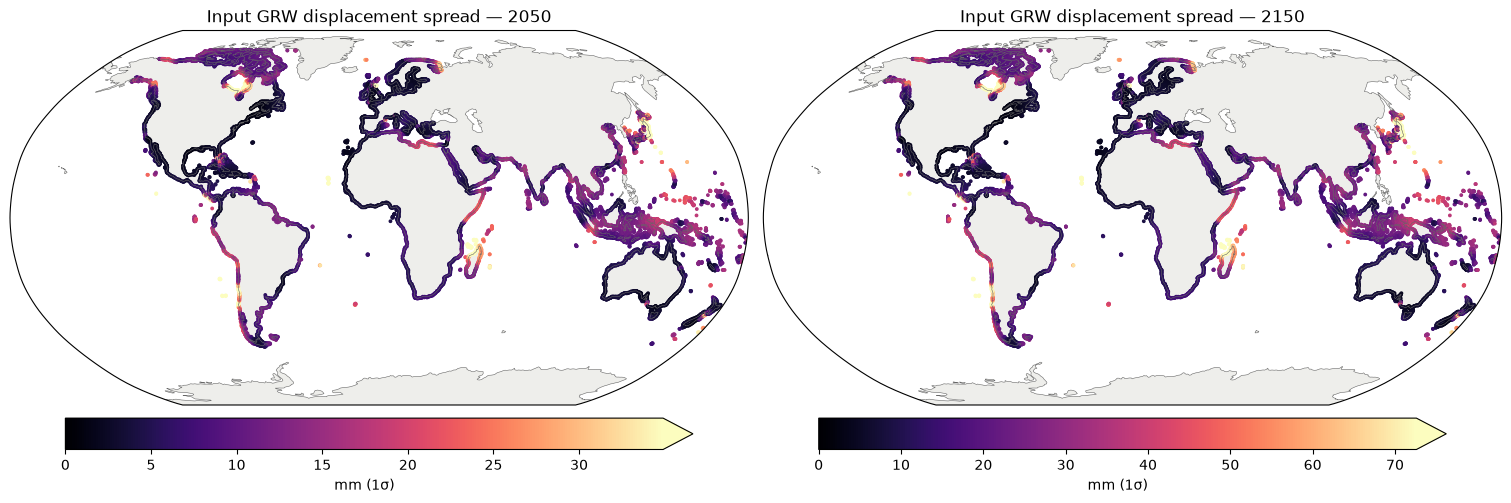

In [4]:
fig, axes = dh.map_axes(1, 2, figsize=(15, 5.5))
for ax, year in zip(axes.flat, [2050, 2150]):
    spread = rec.GRW_ensemble_std.sel(time=str(year)).squeeze() * 1000
    dh.map_points(
        ax,
        rec.lon,
        rec.lat,
        spread,
        f"Input GRW displacement spread — {year}",
        "mm (1σ)",
        cmap="magma",
    )
dh.save_figure(fig, config, "input_grw_spread.png")

## GNSS inputs and accepted supplementary observations

The maps show all supplied GNSS stations. Only stations selected by the production coverage/region rules supplement the reconstruction. Reported uncertainty is the input measurement error; the corrected smoother combines propagated measurement error with spatial scatter. CMR treatment is unchanged.

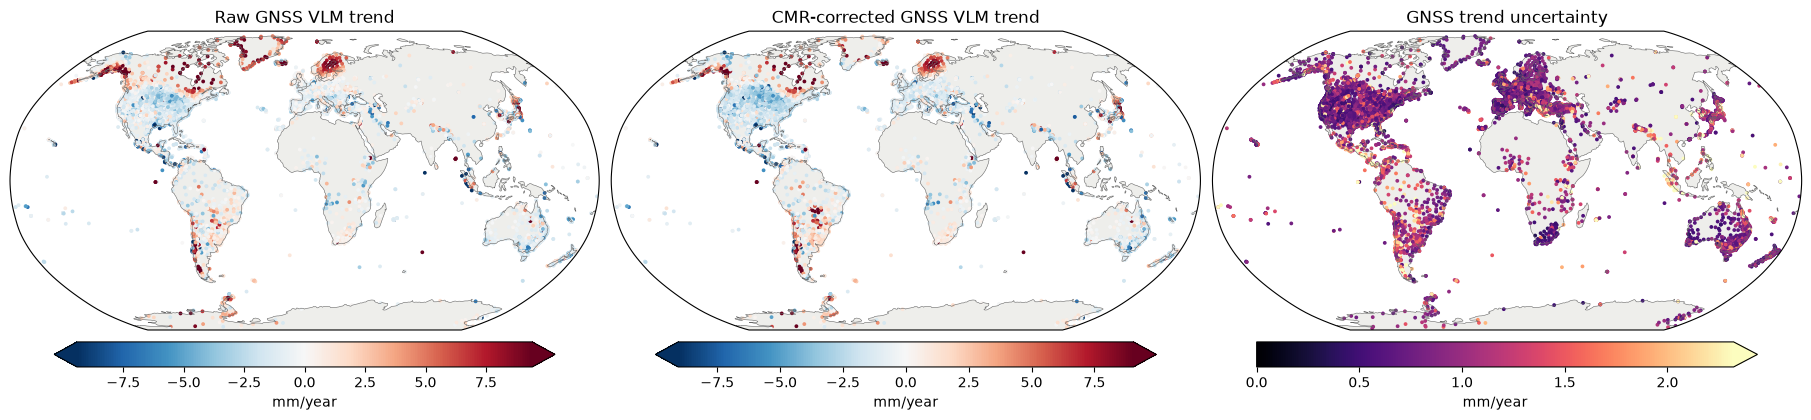

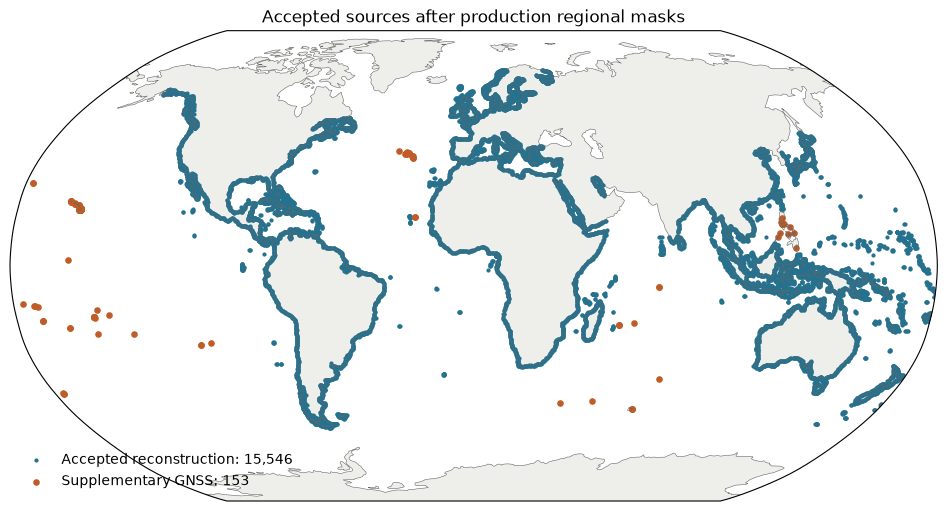

In [5]:
fig, axes = dh.map_axes(1, 3, figsize=(18, 5))
for ax, name, title, cmap in zip(
    axes.flat,
    ["trend", "trend_CMR_corrected", "trend_un"],
    ["Raw GNSS VLM trend", "CMR-corrected GNSS VLM trend", "GNSS trend uncertainty"],
    ["RdBu_r", "RdBu_r", "magma"],
):
    dh.map_points(ax, gps.lon, gps.lat, gps[name], title, "mm/year", cmap=cmap)
dh.save_figure(fig, config, "input_gnss.png")

# Ask the same production functions which source points are accepted.
from oelsmann24_verticallandmotion.vlm_preprocess import (  # noqa: E402
    load_datasets,
    merge_gps_and_vlm_reconstruction,
)

loaded = load_datasets(**config.paths())
accepted, _ = merge_gps_and_vlm_reconstruction(loaded[0], loaded[1])
fig, axes = dh.map_axes(1, 1, figsize=(12, 5))
for kind, label, color in [
    (0, "Accepted reconstruction", "#26718e"),
    (1, "Supplementary GNSS", "#bf5c27"),
]:
    subset = accepted.where(accepted.kind == kind, drop=True)
    axes[0, 0].scatter(
        subset.lon,
        subset.lat,
        s=4 if kind == 0 else 14,
        color=color,
        label=f"{label}: {subset.sizes['x']:,}",
        transform=ccrs.PlateCarree(),
        rasterized=True,
    )
axes[0, 0].legend(loc="lower left", frameon=False)
axes[0, 0].set_title("Accepted sources after production regional masks")
dh.save_figure(fig, config, "input_accepted_sources.png")

## GIA means and standard errors

The sum `rsl_mean + rad_mean` is GIA's sea-surface rate, which is combined with the negative observed land-motion rate. Standard errors of the separate input fields do not by themselves specify the covariance or uncertainty of that sum.

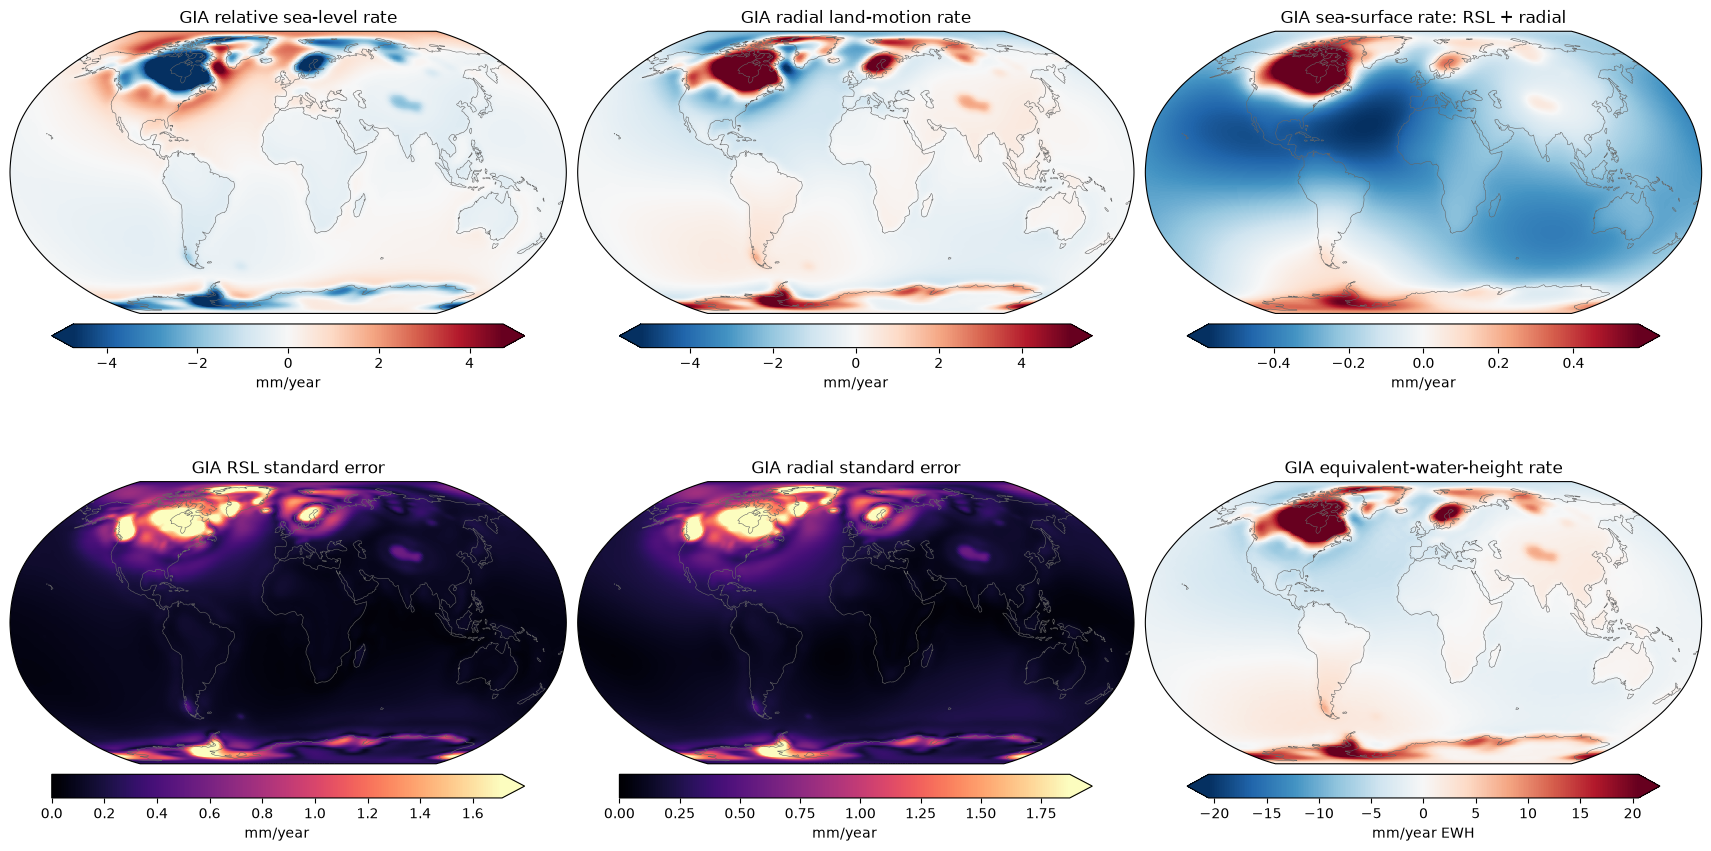

In [6]:
fig, axes = dh.map_axes(2, 3, figsize=(17, 9))
variables = [
    gia.rsl_mean,
    gia.rad_mean,
    gia.rsl_mean + gia.rad_mean,
    gia.rsl_sterr,
    gia.rad_sterr,
    gia.ewh_mean,
]
titles = [
    "GIA relative sea-level rate",
    "GIA radial land-motion rate",
    "GIA sea-surface rate: RSL + radial",
    "GIA RSL standard error",
    "GIA radial standard error",
    "GIA equivalent-water-height rate",
]
for i, (ax, variable, title) in enumerate(zip(axes.flat, variables, titles)):
    dh.map_grid(
        ax,
        variable,
        title,
        "mm/year EWH" if i == 5 else "mm/year",
        cmap="magma" if i in [3, 4] else "RdBu_r",
    )
dh.save_figure(fig, config, "input_gia.png")

## Corrected coastal mask and spatial weights

The module uses a 150 km coastal selection, then tapers observation influence to zero at 100 km from the nearest accepted source. Zero observation weight means GIA fallback. The six city markers use the same locations as the projection notebook.

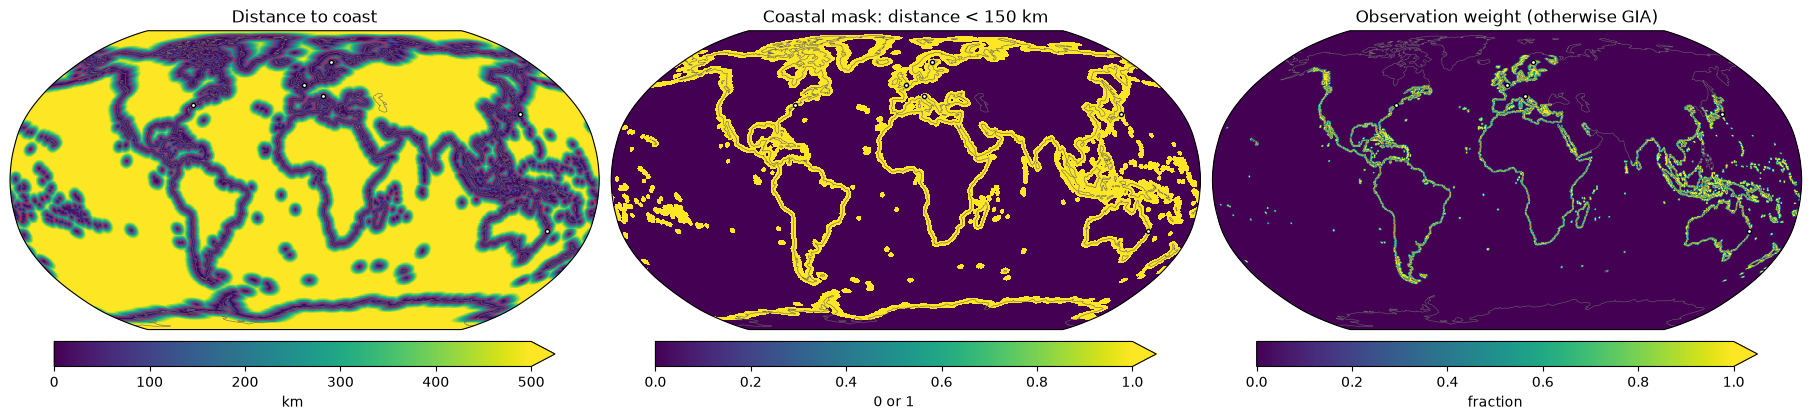

,city,latitude,longitude
0,Venice,45.4300,12.3300
1,Skellefteå,64.7500,21.0000
2,London,51.5074,-0.1278
3,Tokyo,35.6500,139.7700
4,Brisbane,-27.4700,153.0300
5,New York,40.7000,-74.0100


In [7]:
fig, axes = dh.map_axes(1, 3, figsize=(18, 5))
dh.map_grid(
    axes[0, 0],
    abs(fields.z),
    "Distance to coast",
    "km",
    cmap="viridis",
    limits=(0, 500),
)
axes[0, 0].contour(
    fields.lon,
    fields.lat,
    abs(fields.z),
    levels=[150],
    colors="crimson",
    linewidths=0.45,
    transform=ccrs.PlateCarree(),
)
dh.map_grid(
    axes[0, 1],
    (abs(fields.z) < 150).astype(float),
    "Coastal mask: distance < 150 km",
    "0 or 1",
    cmap="viridis",
    limits=(0, 1),
)
dh.map_grid(
    axes[0, 2],
    weights,
    "Observation weight (otherwise GIA)",
    "fraction",
    cmap="viridis",
    limits=(0, 1),
)
for ax in axes.flat:
    dh.mark_cities(ax)
dh.save_figure(fig, config, "input_masks_and_weights.png")
display(pd.DataFrame(dh.CITIES, columns=["city", "latitude", "longitude"]))
for dataset in [rec, gps, gia]:
    dataset.close()

The production package provides the spatial selection, smoothing and blending. This notebook is an inspection tool: it does not define a second implementation of the scientific model. The projection notebook records source/input hashes and dependency versions for its saved outputs.